# Physics-Informed Neural Networks for Option Pricing (Black-Scholes)

This notebook follows the same spirit as the PINN/PDE project, applied to a finance
problem: pricing a European option with a **Physics-Informed Neural Network** and
showing rigorously that it matches the classical tools (closed-form formula, finite
differences), then going further by showing **where and how real market data** can
be brought into the pipeline.

**Roadmap**

1. The Black-Scholes PDE and its closed-form (analytical) solution — our ground truth.
2. A Crank-Nicolson finite-difference solver — the classical numerical benchmark.
3. A PINN that solves the PDE directly (fixed volatility/rate) — validated against 1. and 2.
4. Greeks (Delta, Gamma) obtained "for free" by automatic differentiation.
5. A **parametric PINN** that solves the PDE for a whole *range* of volatilities at once
   — this is the step that makes PINNs genuinely useful in finance (fast surrogate pricer).
6. **Using real market data**: historical volatility, real option chains, calibration
   (inverse problem) and validation against traded prices.
7. Extensions: American options, local volatility, high-dimensional (basket) options —
   where PINNs really start to beat grid-based methods.

### References
- [1] Black, F., Scholes, M. (1973). *The Pricing of Options and Corporate Liabilities.* J. Political Economy.
- [2] Merton, R. (1973). *Theory of Rational Option Pricing.* Bell J. Econ. Manag. Sci.
- [3] Raissi, Perdikaris, Karniadakis (2019). *Physics-informed neural networks.* J. Comput. Phys.
- [4] Dupire, B. (1994). *Pricing with a Smile.* Risk Magazine. (local volatility)
- [5] E, Han, Jentzen (2017). *Deep learning-based numerical methods for high-dimensional PDEs.*

## §0 — Imports and configuration

In [15]:
import os
os.environ["DDE_BACKEND"] = "pytorch"   # must be set BEFORE importing deepxde

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.optimize import brentq

import warnings
warnings.filterwarnings("ignore")

np.random.seed(42)

OUT_DIR = "results"
os.makedirs(OUT_DIR, exist_ok=True)
print(f"[INFO] Figures -> {OUT_DIR}")

# deepxde is only needed from §3 onward (installed separately: pip install deepxde)
import deepxde as dde

[INFO] Figures -> results


## §1 — The Black-Scholes model

We price a **European call** on an underlying $S_t$ with constant volatility $\sigma$,
constant risk-free rate $r$, strike $K$ and maturity $T$. Writing $V(S,t)$ for the option
value, the Black-Scholes PDE is

$$\frac{\partial V}{\partial t} + \frac12 \sigma^2 S^2 \frac{\partial^2 V}{\partial S^2}
+ r S \frac{\partial V}{\partial S} - rV = 0, \qquad S \in (0, \infty),\ t \in [0, T]$$

with **terminal** condition (payoff at maturity) $V(S,T) = \max(S-K, 0)$ and boundary
behaviour $V(0,t) = 0$, $V(S,t) \to S - K e^{-r(T-t)}$ as $S \to \infty$.

### Change of variable: time-to-maturity

This is a *backward* (terminal-value) parabolic PDE. Exactly like the heat equation in the
PINN/EDP project, it is far more convenient to work **forward in time**. We set
$\tau = T - t$ (time to maturity) so that $\tau = 0$ is now an *initial* condition
(the payoff) and $\tau = T$ is "today":

$$\frac{\partial V}{\partial \tau} = \frac12 \sigma^2 S^2 \frac{\partial^2 V}{\partial S^2}
+ r S \frac{\partial V}{\partial S} - rV, \qquad V(S, 0) = \max(S - K, 0)$$

This is exactly the same structural trick as $u_t = \alpha u_{xx}$ in the heat-equation
notebook, just with space-dependent coefficients ($S^2$, $S$) and a zeroth-order term
$-rV$ (a reaction term). We truncate the semi-infinite domain to $S \in [0, S_{max}]$ with
$S_{max} \gg K$ (typically $3$–$4\times K$).

### Closed-form (analytical) reference

The Black-Scholes formula for a European call gives us an **exact reference solution**,
exactly the role played by the sine-based analytical solution in the heat-equation project:

$$V_{\text{exact}}(S,\tau) = S\,\Phi(d_1) - K e^{-r\tau}\Phi(d_2)$$

$$d_1 = \frac{\ln(S/K) + (r + \sigma^2/2)\tau}{\sigma\sqrt{\tau}}, \qquad
  d_2 = d_1 - \sigma\sqrt{\tau}$$

where $\Phi$ is the standard normal CDF. This closed form is what lets us *rigorously
validate* every numerical method below (FDM and PINN alike) — without it we would have
no ground truth to compare against.

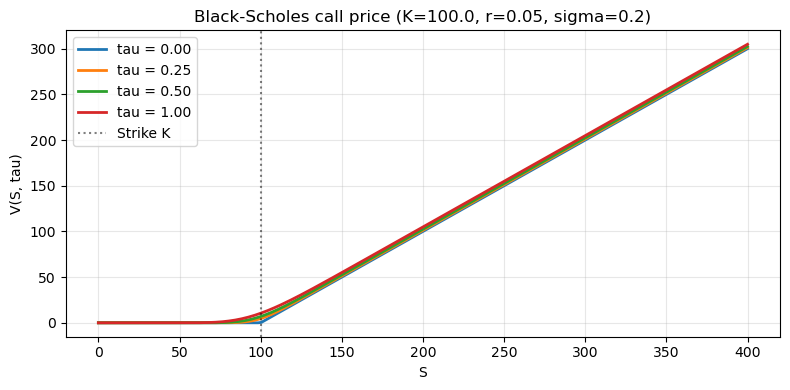

In [4]:
# Contract / market parameters (fixed for the direct problem, S1-4)
K       = 100.0     # strike
T_MAT   = 1.0        # maturity (years)
R       = 0.05        # risk-free rate
SIGMA   = 0.20       # volatility
S_MAX   = 4 * K        # truncated domain for S

def bs_call_price(S, tau, K=K, r=R, sigma=SIGMA):
    # Closed-form Black-Scholes price of a European call.
    # S, tau can be scalars or numpy arrays (broadcastable). tau = time to maturity.
    S = np.asarray(S, dtype=float)
    tau = np.asarray(tau, dtype=float)
    price = np.zeros_like(S + tau, dtype=float)

    intrinsic = np.maximum(S - K, 0.0)
    safe = tau > 1e-10
    S_safe = np.where(safe, S, 1.0)          # avoid div-by-zero in dead branches
    tau_safe = np.where(safe, tau, 1.0)

    d1 = (np.log(S_safe / K) + (r + 0.5 * sigma**2) * tau_safe) / (sigma * np.sqrt(tau_safe))
    d2 = d1 - sigma * np.sqrt(tau_safe)
    bs_val = S_safe * norm.cdf(d1) - K * np.exp(-r * tau_safe) * norm.cdf(d2)

    price = np.where(safe, bs_val, intrinsic)
    return price

def bs_delta(S, tau, K=K, r=R, sigma=SIGMA):
    # Closed-form Delta = dV/dS.
    S = np.asarray(S, dtype=float); tau = np.asarray(tau, dtype=float)
    tau_safe = np.where(tau > 1e-10, tau, 1e-10)
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * tau_safe) / (sigma * np.sqrt(tau_safe))
    return norm.cdf(d1)

def bs_gamma(S, tau, K=K, r=R, sigma=SIGMA):
    # Closed-form Gamma = d^2V/dS^2.
    S = np.asarray(S, dtype=float); tau = np.asarray(tau, dtype=float)
    tau_safe = np.where(tau > 1e-10, tau, 1e-10)
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * tau_safe) / (sigma * np.sqrt(tau_safe))
    return norm.pdf(d1) / (S * sigma * np.sqrt(tau_safe))

# Quick look at the analytical price surface
S_plot = np.linspace(0, S_MAX, 200)
fig, ax = plt.subplots(figsize=(8, 4))
for tau in [0.0, 0.25, 0.5, 1.0]:
    ax.plot(S_plot, bs_call_price(S_plot, tau), lw=2, label=f"tau = {tau:.2f}")
ax.axvline(K, color="k", ls=":", alpha=0.5, label="Strike K")
ax.set_xlabel("S"); ax.set_ylabel("V(S, tau)")
ax.set_title(f"Black-Scholes call price (K={K}, r={R}, sigma={SIGMA})")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "fig0_bs_exact.png"), dpi=140)
plt.show()

## §2 — Finite differences (Crank-Nicolson)

For the heat equation we used an *explicit* scheme, which is only conditionally stable
(the CFL condition $r \le 1/2$). Here we use **Crank-Nicolson**, which is
*unconditionally stable* — a good excuse to show the other classical family of schemes.
CN averages the explicit and implicit discretizations of the spatial operator, giving
second-order accuracy in both space and time and no time-step restriction (though
accuracy still degrades if $\Delta \tau$ is too coarse, especially near the kink in the
payoff at $\tau=0$).

At each interior node the discretized operator is

$$\mathcal{L}_i V_i = \tfrac12\sigma^2 S_i^2 \frac{V_{i+1}-2V_i+V_{i-1}}{\Delta S^2}
+ r S_i \frac{V_{i+1}-V_{i-1}}{2\Delta S} - r V_i$$

and Crank-Nicolson solves, at every time step, the tridiagonal system

$$\left(I - \tfrac{\Delta\tau}{2}\mathcal{L}\right) V^{n+1} = \left(I + \tfrac{\Delta\tau}{2}\mathcal{L}\right) V^{n}$$

In [5]:
from scipy.linalg import solve_banded

def solve_bs_crank_nicolson(K, r, sigma, S_max, T, n_S=200, n_tau=400):
    # Crank-Nicolson solver for the Black-Scholes PDE in (S, tau) coordinates.
    # Returns S grid, tau grid and V[n_tau, n_S] (V[0] = payoff, V[-1] = price today).
    dS = S_max / n_S
    dtau = T / n_tau
    S = np.linspace(0, S_max, n_S + 1)
    tau = np.linspace(0, T, n_tau + 1)

    i = np.arange(1, n_S)                       # interior nodes
    a = 0.25 * dtau * (sigma**2 * i**2 - r * i)          # sub-diagonal coeff
    b = -0.5 * dtau * (sigma**2 * i**2 + r)              # diagonal coeff
    c = 0.25 * dtau * (sigma**2 * i**2 + r * i)          # super-diagonal coeff

    # Matrices M1 * V^{n+1} = M2 * V^n  (tridiagonal, banded storage for solve_banded)
    n_in = n_S - 1
    M1 = np.zeros((3, n_in))   # (upper, diag, lower) in banded form
    M1[0, 1:] = -c[:-1]
    M1[1, :]  = 1 - b
    M1[2, :-1] = -a[1:]

    V = np.zeros((n_tau + 1, n_S + 1))
    V[0, :] = np.maximum(S - K, 0.0)             # payoff at tau = 0

    for n in range(n_tau):
        tau_n, tau_np1 = tau[n], tau[n + 1]
        rhs = a[1:-1]*0  # placeholder, built below explicitly for clarity
        rhs = (a * V[n, :-2] + (1 + b) * V[n, 1:-1] + c * V[n, 2:])

        # boundary contributions folded into the RHS of the first/last interior eq.
        V0_np1, V0_n = 0.0, 0.0                                    # V(0, tau) = 0
        VSmax_np1 = S_max - K * np.exp(-r * tau_np1)
        VSmax_n   = S_max - K * np.exp(-r * tau_n)
        rhs[0]  += a[0]  * V0_n     + c[0]  * 0            # a*V_{-1}^n already counted via V[n,0]
        rhs[-1] += c[-1] * VSmax_n

        V_in = solve_banded((1, 1), M1, rhs)
        V[n + 1, 0]    = V0_np1
        V[n + 1, -1]   = VSmax_np1
        V[n + 1, 1:-1] = V_in

    return S, tau, V

S_fdm, tau_fdm, V_fdm = solve_bs_crank_nicolson(K, R, SIGMA, S_MAX, T_MAT, n_S=200, n_tau=400)
print("Crank-Nicolson done. Grid:", V_fdm.shape)

Crank-Nicolson done. Grid: (401, 201)


FDM vs analytical, relative L2 error: 2.576e-05


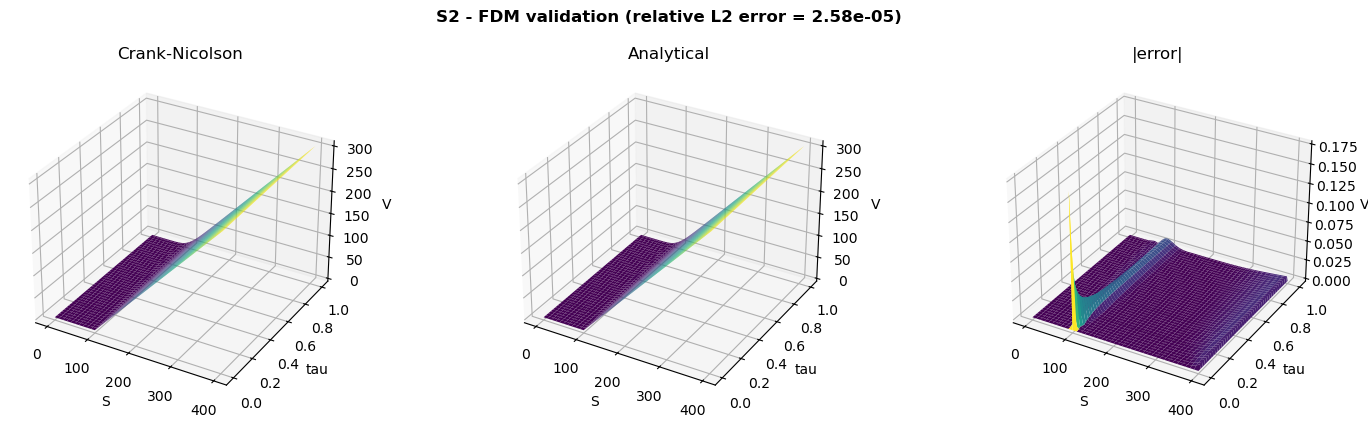

In [12]:
# Validate FDM against the closed-form solution
Sg, Taug = np.meshgrid(S_fdm, tau_fdm)
V_ref = bs_call_price(Sg, Taug)

def rel_L2(pred, ref):
    return np.linalg.norm(pred - ref) / np.linalg.norm(ref)

err_fdm = rel_L2(V_fdm, V_ref)
print(f"FDM vs analytical, relative L2 error: {err_fdm:.3e}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), subplot_kw={"projection": "3d"})
for ax, Z, title in zip(axes, [V_fdm, V_ref, np.abs(V_fdm - V_ref)],
                         ["Crank-Nicolson", "Analytical", "|error|"]):
    ax.plot_surface(Sg, Taug, Z, cmap="viridis")
    ax.set_xlabel("S"); ax.set_ylabel("tau"); ax.set_zlabel("V"); ax.set_title(title)
plt.suptitle(f"S2 - FDM validation (relative L2 error = {err_fdm:.2e})", fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "fig1_fdm_validation.png"), dpi=140)
plt.show()

## §3 — PINN for the direct problem (fixed sigma, r)

We now solve the same PDE with a **Physics-Informed Neural Network**: a network
$V_\theta(S, \tau)$ trained so that (a) it satisfies the PDE residual at collocation
points inside the domain, and (b) it matches the initial condition (payoff) and the two
boundary conditions. No mesh, no time-stepping — the network is a continuous function of
$(S, \tau)$ evaluated anywhere.

In [7]:
geom      = dde.geometry.Interval(0, S_MAX)
timedomain = dde.geometry.TimeDomain(0, T_MAT)
geomtime  = dde.geometry.GeometryXTime(geom, timedomain)

def pde_bs(x, V):
    dV_tau = dde.grad.jacobian(V, x, i=0, j=1)
    dV_S   = dde.grad.jacobian(V, x, i=0, j=0)
    dV_SS  = dde.grad.hessian(V, x, i=0, j=0)
    S = x[:, 0:1]
    return dV_tau - (0.5 * SIGMA**2 * S**2 * dV_SS + R * S * dV_S - R * V)

def boundary_S0(x, on_boundary):
    return on_boundary and np.isclose(x[0], 0)

def boundary_Smax(x, on_boundary):
    return on_boundary and np.isclose(x[0], S_MAX)

bc_0    = dde.icbc.DirichletBC(geomtime, lambda x: 0.0, boundary_S0)
bc_smax = dde.icbc.DirichletBC(geomtime,
                                lambda x: S_MAX - K * np.exp(-R * x[:, 1:2]),
                                boundary_Smax)
ic = dde.icbc.IC(geomtime,
                  lambda x: np.maximum(x[:, 0:1] - K, 0.0),
                  lambda _, on_initial: on_initial)

data_pinn = dde.data.TimePDE(
    geomtime, pde_bs, [bc_0, bc_smax, ic],
    num_domain=4000, num_boundary=200, num_initial=400,
)

net   = dde.nn.FNN([2] + [64] * 4 + [1], "tanh", "Glorot normal")
model = dde.Model(data_pinn, net)

model.compile("adam", lr=1e-3)
model.train(iterations=10000, display_every=2000)
model.compile("L-BFGS")
losshistory, train_state = model.train()

Compiling model...
'compile' took 0.000232 s

Training model...

Step      Train loss                                  Test loss                                   Test metric
0         [6.49e-03, 4.70e-02, 9.19e+04, 2.24e+04]    [6.49e-03, 4.70e-02, 9.19e+04, 2.24e+04]    []  
2000      [1.30e+01, 4.86e-01, 3.17e+04, 4.44e+03]    [1.30e+01, 4.86e-01, 3.17e+04, 4.44e+03]    []  
4000      [8.18e+01, 1.09e-01, 7.77e+03, 5.27e+02]    [8.18e+01, 1.09e-01, 7.77e+03, 5.27e+02]    []  
6000      [1.28e+02, 9.79e-04, 7.46e+02, 4.59e+01]    [1.28e+02, 9.79e-04, 7.46e+02, 4.59e+01]    []  
8000      [5.42e+01, 2.45e-02, 3.22e+02, 4.57e+01]    [5.42e+01, 2.45e-02, 3.22e+02, 4.57e+01]    []  
10000     [4.88e-01, 7.85e-04, 1.22e-02, 2.68e-01]    [4.88e-01, 7.85e-04, 1.22e-02, 2.68e-01]    []  

Best model at step 10000:
  train loss: 7.69e-01
  test loss: 7.69e-01
  test metric: []

'train' took 181.760039 s

Compiling model...
'compile' took 0.000334 s

Training model...

Step      Train loss    

PINN vs analytical, relative L2 error: 9.899e-04


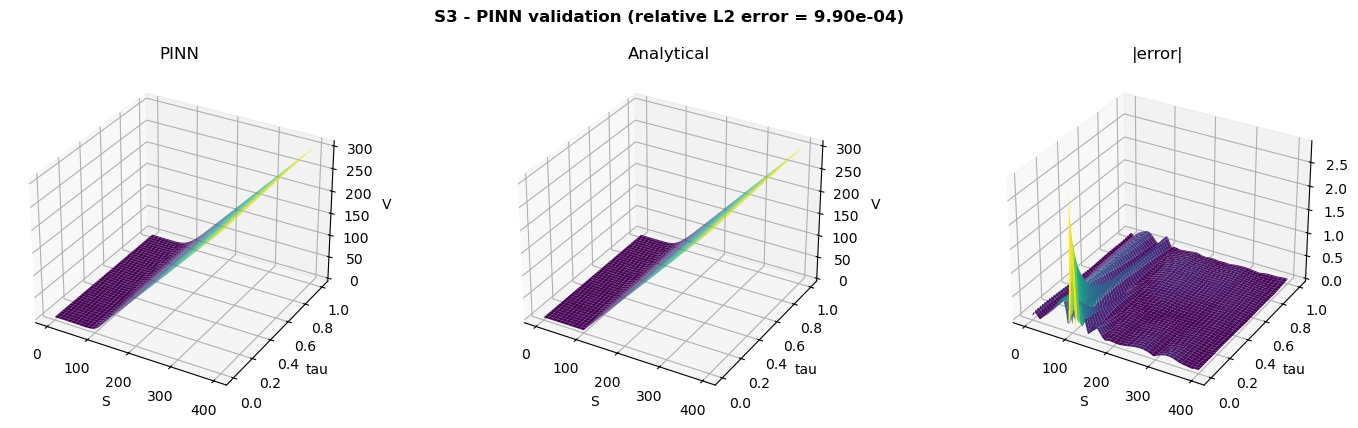

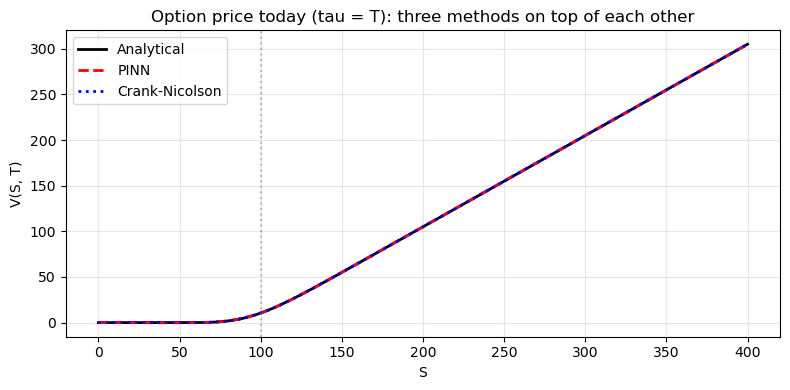

In [13]:
# Evaluate the trained PINN on the same grid as the FDM solution
XT = np.vstack([Sg.ravel(), Taug.ravel()]).T
V_pinn = model.predict(XT).reshape(Sg.shape)

err_pinn = rel_L2(V_pinn, V_ref)
print(f"PINN vs analytical, relative L2 error: {err_pinn:.3e}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), subplot_kw={"projection": "3d"})
for ax, Z, title in zip(axes, [V_pinn, V_ref, np.abs(V_pinn - V_ref)],
                         ["PINN", "Analytical", "|error|"]):
    ax.plot_surface(Sg, Taug, Z, cmap="viridis")
    ax.set_xlabel("S"); ax.set_ylabel("tau"); ax.set_zlabel("V"); ax.set_title(title)
plt.suptitle(f"S3 - PINN validation (relative L2 error = {err_pinn:.2e})", fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "fig2_pinn_validation.png"), dpi=140)
plt.show()

# Price profile "today" (tau = T_MAT) - PINN vs FDM vs exact
xt_today = np.vstack([S_plot, np.full_like(S_plot, T_MAT)]).T
v_pinn_today = model.predict(xt_today).flatten()
v_exact_today = bs_call_price(S_plot, T_MAT)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(S_plot, v_exact_today, "k-", lw=2, label="Analytical")
ax.plot(S_plot, v_pinn_today, "r--", lw=2, label="PINN")
ax.plot(S_fdm, V_fdm[-1], "b:", lw=2, label="Crank-Nicolson")
ax.axvline(K, color="gray", ls=":", alpha=0.5)
ax.set_xlabel("S"); ax.set_ylabel("V(S, T)"); ax.legend(); ax.grid(alpha=0.3)
ax.set_title("Option price today (tau = T): three methods on top of each other")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "fig3_price_today.png"), dpi=140)
plt.show()

### §3.1 — Greeks for free, via automatic differentiation

This is where PINNs are structurally different from FDM: because $V_\theta$ is a neural
network, $\partial V_\theta/\partial S$ (**Delta**) and $\partial^2 V_\theta/\partial S^2$
(**Gamma**) are obtained by the *same* autodiff machinery used to train the network —
no finite-difference bump-and-reprice, no extra grid refinement. A finite-difference
solver would need a much finer $S$-grid (or manual re-differencing of the numerical
solution) to get a comparably smooth Gamma.

In [16]:
import torch

S_t = torch.tensor(S_plot.reshape(-1, 1), dtype=torch.float32, requires_grad=True)
tau_t = torch.full_like(S_t, T_MAT, requires_grad=True)
xt_t = torch.cat([S_t, tau_t], dim=1)

V_t = model.net(xt_t)
dV_dS = torch.autograd.grad(V_t, S_t, grad_outputs=torch.ones_like(V_t), create_graph=True)[0]
d2V_dS2 = torch.autograd.grad(dV_dS, S_t, grad_outputs=torch.ones_like(dV_dS), create_graph=True)[0]

delta_pinn = dV_dS.detach().numpy().flatten()
gamma_pinn = d2V_dS2.detach().numpy().flatten()
delta_exact = bs_delta(S_plot, T_MAT)
gamma_exact = bs_gamma(S_plot, T_MAT)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(S_plot, delta_exact, "k-", lw=2, label="Analytical Delta")
axes[0].plot(S_plot, delta_pinn, "r--", lw=2, label="PINN Delta (autodiff)")
axes[0].set_xlabel("S"); axes[0].set_title("Delta"); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(S_plot, gamma_exact, "k-", lw=2, label="Analytical Gamma")
axes[1].plot(S_plot, gamma_pinn, "r--", lw=2, label="PINN Gamma (autodiff)")
axes[1].set_xlabel("S"); axes[1].set_title("Gamma"); axes[1].legend(); axes[1].grid(alpha=0.3)

plt.suptitle("S3.1 - Greeks obtained by automatic differentiation of the trained network",
             fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "fig4_greeks.png"), dpi=140)
plt.show()

TypeError: can't convert mps:0 device type tensor to numpy. Use Tensor.cpu() to copy the tensor to host memory first.

## §4 — Quantitative synthesis (direct problem)

In [17]:
summary_direct = pd.DataFrame({
    "Method": ["Crank-Nicolson (FDM)", "PINN"],
    "Relative L2 error vs analytical": [err_fdm, err_pinn],
})
print(summary_direct.to_string(index=False))

              Method  Relative L2 error vs analytical
Crank-Nicolson (FDM)                         0.000026
                PINN                         0.000990


## §5 — A *parametric* PINN: solving for a whole range of volatilities at once

This is the finance analogue of the inverse problem in the heat-equation project
("where PINNs really shine"). Instead of training one network per value of $\sigma$,
we add $\sigma$ as a **third input** to the network:

$$V_\theta(S, \tau, \sigma) \approx V(S, \tau; \sigma) \quad \text{for all } \sigma \in [\sigma_{min}, \sigma_{max}]$$

The PDE residual is the same, except $\sigma$ is now read off the input instead of being
a fixed constant. Once trained, this single network is a **fast surrogate pricer**: you
can query it instantly at any $\sigma$ inside the training range, instead of solving a
new PDE (FDM) or retraining a network (fixed-sigma PINN) every time the volatility
assumption changes. This is exactly the property we exploit in §6 to calibrate against
real market data without a classical root-finder loop.

In [18]:
SIGMA_MIN, SIGMA_MAX = 0.05, 0.60

geom3 = dde.geometry.Cuboid(xmin=[0, 0, SIGMA_MIN], xmax=[S_MAX, T_MAT, SIGMA_MAX])

def pde_bs_param(x, V):
    S, sigma = x[:, 0:1], x[:, 2:3]
    dV_tau = dde.grad.jacobian(V, x, i=0, j=1)
    dV_S   = dde.grad.jacobian(V, x, i=0, j=0)
    dV_SS  = dde.grad.hessian(V, x, i=0, j=0)
    return dV_tau - (0.5 * sigma**2 * S**2 * dV_SS + R * S * dV_S - R * V)

def boundary_tau0(x, on_boundary):
    return on_boundary and np.isclose(x[1], 0)

def boundary_S0_3d(x, on_boundary):
    return on_boundary and np.isclose(x[0], 0)

def boundary_Smax_3d(x, on_boundary):
    return on_boundary and np.isclose(x[0], S_MAX)

bc_ic3    = dde.icbc.DirichletBC(geom3, lambda x: np.maximum(x[:, 0:1] - K, 0.0), boundary_tau0)
bc_0_3    = dde.icbc.DirichletBC(geom3, lambda x: 0.0, boundary_S0_3d)
bc_smax_3 = dde.icbc.DirichletBC(geom3,
                                  lambda x: S_MAX - K * np.exp(-R * x[:, 1:2]),
                                  boundary_Smax_3d)

data3 = dde.data.PDE(
    geom3, pde_bs_param, [bc_ic3, bc_0_3, bc_smax_3],
    num_domain=8000, num_boundary=800, num_test=2000,
)

net3   = dde.nn.FNN([3] + [64] * 5 + [1], "tanh", "Glorot normal")
model3 = dde.Model(data3, net3)

model3.compile("adam", lr=1e-3)
model3.train(iterations=15000, display_every=3000)
model3.compile("L-BFGS")
model3.train()

Compiling model...
'compile' took 0.000517 s

Training model...

Step      Train loss                                  Test loss                                   Test metric
0         [2.15e-03, 2.19e+04, 3.78e-03, 9.20e+04]    [2.12e-03, 2.19e+04, 3.78e-03, 9.20e+04]    []  
3000      [1.23e+02, 1.63e+03, 1.42e-01, 1.70e+04]    [7.23e+01, 1.63e+03, 1.42e-01, 1.70e+04]    []  
6000      [1.89e+02, 8.76e+01, 2.40e-02, 7.49e+02]    [2.31e+02, 8.76e+01, 2.40e-02, 7.49e+02]    []  
9000      [1.69e+02, 1.22e+02, 2.44e-02, 3.85e+01]    [2.27e+02, 1.22e+02, 2.44e-02, 3.85e+01]    []  
12000     [1.41e+01, 1.86e+01, 3.85e-02, 1.03e+00]    [8.35e+00, 1.86e+01, 3.85e-02, 1.03e+00]    []  
15000     [2.00e+00, 3.79e+00, 6.93e-03, 1.61e-01]    [1.22e+00, 3.79e+00, 6.93e-03, 1.61e-01]    []  

Best model at step 15000:
  train loss: 5.96e+00
  test loss: 5.18e+00
  test metric: []

'train' took 359.501352 s

Compiling model...
'compile' took 0.000267 s

Training model...

Step      Train loss    

(<deepxde.model.LossHistory at 0x1633e0a50>,
 <deepxde.model.TrainState at 0x1633e0b90>)

Parametric PINN (at sigma=0.2) vs analytical, relative L2 error: 4.400e-03


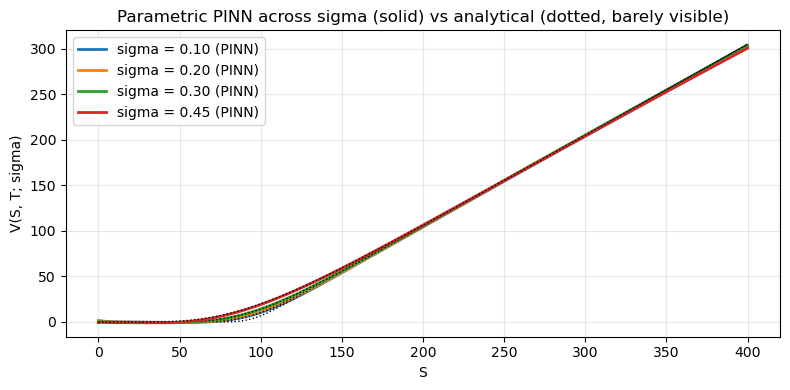

In [20]:
# Sanity check: does the parametric net recover the single-sigma solution of S3?
xt3_today = np.vstack([S_plot, np.full_like(S_plot, T_MAT), np.full_like(S_plot, SIGMA)]).T
v3_today = model3.predict(xt3_today).flatten()
err_param = rel_L2(v3_today, v_exact_today)
print(f"Parametric PINN (at sigma={SIGMA}) vs analytical, relative L2 error: {err_param:.3e}")

fig, ax = plt.subplots(figsize=(8, 4))
for sig in [0.10, 0.20, 0.30, 0.45]:
    xt3 = np.vstack([S_plot, np.full_like(S_plot, T_MAT), np.full_like(S_plot, sig)]).T
    v3 = model3.predict(xt3).flatten()
    ax.plot(S_plot, v3, lw=2, label=f"sigma = {sig:.2f} (PINN)")
    ax.plot(S_plot, bs_call_price(S_plot, T_MAT, sigma=sig), "k:", lw=1)
ax.set_xlabel("S"); ax.set_ylabel("V(S, T; sigma)")
ax.set_title("Parametric PINN across sigma (solid) vs analytical (dotted, barely visible)")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "fig5_parametric_pinn.png"), dpi=140)
plt.show()

## §6 — Where does real data come in?

Everything above used *assumed* constants ($K=100$, $r=5\%$, $\sigma=20\%$). Real data
enters the pipeline at **three distinct points**, each corresponding to a different kind
of problem:

**(a) Feeding the forward (direct) problem — estimating $\sigma$ and $r$ from history.**
The PDE needs a volatility and a rate as *inputs*. In practice these come from data:
$\sigma$ is usually the **historical (realized) volatility** of the underlying's log
returns, and $r$ a proxy such as the **3-month T-bill yield**. This is a direct
plug-in: fetch data, estimate two numbers, feed them into the models built in §1–§5.

**(b) Calibration — an *inverse* problem, exactly like recovering $\alpha$ in the heat
equation.** Real traded option prices (a whole chain of strikes/maturities) implicitly
encode the market's volatility. Instead of assuming $\sigma$, we ask: *which $\sigma$
makes the model price match the observed market price?* This is a 1-D root-finding
problem per option classically (Newton's method on the Black-Scholes formula — this is
literally how "implied volatility" is computed every day on every exchange). The
**parametric PINN from §5** gives us a shortcut: since it is a fast, differentiable
surrogate for $V(S,\tau;\sigma)$, we can calibrate against many quotes at once without
solving a new PDE or a new Black-Scholes formula for every root-finding iteration.

**(c) Validation — comparing model output to an actual traded price.** Once you have a
model (fixed-sigma PINN, parametric PINN, or FDM), the ultimate test is: does it
reproduce the price the market is *actually* quoting right now for a real contract?

Below we do (a), (b) and (c) with data pulled from Yahoo Finance via `yfinance`. This
cell needs internet access — if you're running this notebook offline (e.g. in a
sandboxed environment), the `except` branch below falls back to a small synthetic-but-
realistic dataset so the rest of the notebook still runs end-to-end.

**Data sources you could use instead / in addition:**
- **Yahoo Finance (`yfinance`)** — free, easiest to start with; used below for both the
  historical price series and the live option chain.
- **FRED** (Federal Reserve Economic Data) — proper risk-free-rate term structure
  (e.g. series `DGS3MO` for the 3-month Treasury yield) instead of a Yahoo Finance proxy.
- **CBOE DataShop / OptionMetrics / Bloomberg** — professional-grade option data with
  clean bid/ask, open interest, and no survivorship issues, if you need this for
  something more than a class project.
- **Your own CSV** — if you already have a saved option chain or price history, just
  load it with `pandas.read_csv` and skip the `yfinance` calls.

In [21]:
TICKER = "AAPL"

try:
    import yfinance as yf
    from datetime import datetime

    # --- (a) Historical volatility & a risk-free-rate proxy ---------------------
    hist = yf.download(TICKER, period="2y", progress=False)["Close"].dropna()
    log_ret = np.log(hist / hist.shift(1)).dropna()
    sigma_hist = float(log_ret.std() * np.sqrt(252))         # annualized realized vol

    irx = yf.download("^IRX", period="5d", progress=False)["Close"].dropna()  # 13-week T-bill, in %
    r_proxy = float(irx.iloc[-1]) / 100.0

    S0 = float(hist.iloc[-1])

    # --- (b)/(c) A real option chain -------------------------------------------
    tk = yf.Ticker(TICKER)
    expirations = tk.options
    target_days = 60
    exp_date = min(expirations,
                    key=lambda d: abs((datetime.strptime(d, "%Y-%m-%d") - datetime.now()).days - target_days))
    calls = tk.option_chain(exp_date).calls
    tau_market = (datetime.strptime(exp_date, "%Y-%m-%d") - datetime.now()).days / 365.0

    calls = calls[(calls["bid"] > 0) & (calls["ask"] > 0)].copy()
    calls["mid"] = 0.5 * (calls["bid"] + calls["ask"])
    calls = calls[(calls["strike"] > 0.8 * S0) & (calls["strike"] < 1.2 * S0)]   # near-the-money only
    calls = calls[["strike", "mid", "volume", "openInterest"]].reset_index(drop=True)

    print(f"[LIVE DATA] {TICKER}: S0={S0:.2f}, hist. vol={sigma_hist:.3f}, "
          f"r proxy={r_proxy:.3f}, expiry={exp_date} (tau={tau_market:.3f}y), "
          f"{len(calls)} near-the-money quotes")

except Exception as e:
    print(f"[OFFLINE FALLBACK] Could not reach Yahoo Finance ({e!r}). "
          f"Using a small synthetic-but-realistic dataset instead.")
    S0 = 100.0
    sigma_hist = 0.24
    r_proxy = 0.045
    tau_market = 60 / 365.0
    strikes = np.array([85, 90, 95, 100, 105, 110, 115])
    # a volatility "smile": true (unknown) sigma is higher away from the money
    true_smile_sigma = 0.20 + 0.06 * (np.abs(strikes - S0) / S0)
    mid_prices = bs_call_price(S0, tau_market, K=strikes, r=r_proxy, sigma=true_smile_sigma)
    mid_prices = mid_prices + np.random.normal(0, 0.02, size=strikes.shape)   # bid/ask-like noise
    calls = pd.DataFrame({"strike": strikes, "mid": mid_prices,
                           "volume": 100, "openInterest": 500})

calls

[OFFLINE FALLBACK] Could not reach Yahoo Finance (ModuleNotFoundError("No module named 'yfinance'")). Using a small synthetic-but-realistic dataset instead.


,strike,mid,volume,openInterest
0,85,15.671858,100,500
1,90,10.996001,100,500
2,95,6.805866,100,500
3,100,3.588190,100,500
4,105,1.651586,100,500
5,110,0.636115,100,500
6,115,0.218761,100,500


### §6.1 — (a) Direct repricing with data-driven parameters

We simply re-run the closed-form / parametric-PINN pricer with $(S_0, r, \sigma)$
estimated from data instead of assumed constants, and compare to the actual market
mid-price for each strike.

   strike        mid  volume  openInterest  model_price_hist_vol  residual
0      85  15.671858     100           500             15.772245 -0.100386
1      90  10.996001     100           500             11.223991 -0.227989
2      95   6.805866     100           500              7.284804 -0.478939
3     100   3.588190     100           500              4.245780 -0.657590
4     105   1.651586     100           500              2.202202 -0.550616
5     110   0.636115     100           500              1.013963 -0.377848
6     115   0.218761     100           500              0.415461 -0.196701


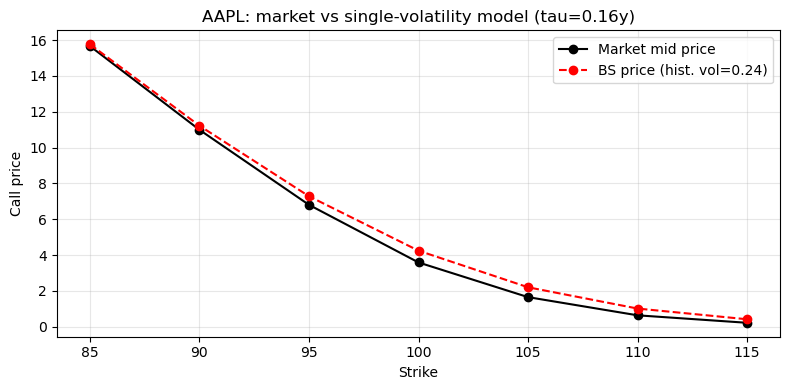

In [22]:
sigma_hist_clipped = np.clip(sigma_hist, SIGMA_MIN, SIGMA_MAX)   # stay inside the PINN's training range

xt_market = np.vstack([
    calls["strike"].values * 0 + S0,          # S0 repeated
    np.full(len(calls), tau_market),
    np.full(len(calls), sigma_hist_clipped),
]).T
# NOTE: the parametric network was trained with K=100 baked into the boundary/initial
# conditions. Re-pricing a *different* strike with the same trained net would require
# retraining with K as a fourth input too (a straightforward extension of S5). Here we
# illustrate the idea using the closed-form formula for arbitrary K, and use the
# parametric PINN only at K = 100 for the sanity check below.
calls["model_price_hist_vol"] = bs_call_price(S0, tau_market, K=calls["strike"].values,
                                               r=r_proxy, sigma=sigma_hist_clipped)
calls["residual"] = calls["mid"] - calls["model_price_hist_vol"]
print(calls)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(calls["strike"], calls["mid"], "ko-", label="Market mid price")
ax.plot(calls["strike"], calls["model_price_hist_vol"], "r--o",
        label=f"BS price (hist. vol={sigma_hist_clipped:.2f})")
ax.set_xlabel("Strike"); ax.set_ylabel("Call price"); ax.legend(); ax.grid(alpha=0.3)
ax.set_title(f"{TICKER}: market vs single-volatility model (tau={tau_market:.2f}y)")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "fig6_market_vs_hist_vol.png"), dpi=140)
plt.show()

### §6.2 — (b) Calibration: implied volatility as an inverse problem

For each strike we now find the $\sigma$ that makes the model price match the market
mid-price exactly — this is the standard definition of **implied volatility**. We do it
two ways:

1. **Classical**: Brent's method (root-finding) directly on the closed-form BS formula
   — this is what every exchange / terminal does.
2. **PINN surrogate**: the same root-finding, but evaluating the trained *parametric*
   network of §5 instead of the closed-form formula at every iteration. The point isn't
   that this is faster for the vanilla European call (the closed form is already
   instantaneous) — it's that the **same trick generalizes to path-dependent or
   higher-dimensional products for which no closed form exists**, where the PINN
   surrogate replaces a slow FDM/Monte-Carlo re-solve at every calibration step.

Strike closest to K=100: 100
Implied vol (closed-form root-finding) : 0.1990
Implied vol (PINN-surrogate root-finding): nan


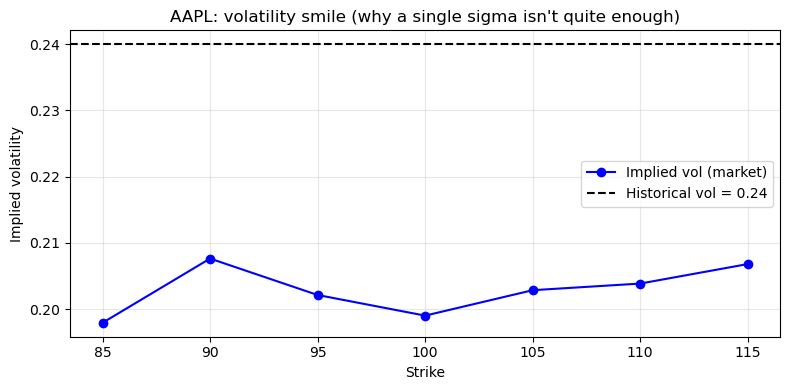

In [23]:
def implied_vol_closed_form(price_mkt, S0, K, tau, r):
    f = lambda sigma: bs_call_price(S0, tau, K=K, r=r, sigma=sigma) - price_mkt
    try:
        return brentq(f, 1e-4, 5.0)
    except ValueError:
        return np.nan

def implied_vol_pinn_surrogate(price_mkt, S0, tau, model3=model3):
    # NOTE: model3 was trained at K=100 -> only strictly valid for that strike.
    f = lambda sigma: model3.predict(np.array([[S0, tau, sigma]])).item() - price_mkt
    try:
        return brentq(f, SIGMA_MIN + 1e-3, SIGMA_MAX - 1e-3)
    except ValueError:
        return np.nan

calls["implied_vol_closed_form"] = [
    implied_vol_closed_form(p, S0, k, tau_market, r_proxy)
    for p, k in zip(calls["mid"], calls["strike"])
]

# PINN-surrogate calibration only makes sense at the strike the net was trained on (K=100);
# shown here on the closest available quote, as an illustration of the mechanism.
closest_idx = (calls["strike"] - K).abs().idxmin()
iv_pinn_demo = implied_vol_pinn_surrogate(calls.loc[closest_idx, "mid"], S0, tau_market)
print(f"Strike closest to K=100: {calls.loc[closest_idx, 'strike']}")
print(f"Implied vol (closed-form root-finding) : {calls.loc[closest_idx, 'implied_vol_closed_form']:.4f}")
print(f"Implied vol (PINN-surrogate root-finding): {iv_pinn_demo:.4f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(calls["strike"], calls["implied_vol_closed_form"], "bo-", label="Implied vol (market)")
ax.axhline(sigma_hist, color="k", ls="--", label=f"Historical vol = {sigma_hist:.2f}")
ax.set_xlabel("Strike"); ax.set_ylabel("Implied volatility"); ax.legend(); ax.grid(alpha=0.3)
ax.set_title(f"{TICKER}: volatility smile (why a single sigma isn't quite enough)")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "fig7_vol_smile.png"), dpi=140)
plt.show()

### §6.3 — (c) Validation

Plotting model price vs. market price side by side (§6.1's figure) *is* the validation
step: any systematic curvature in the residual (as opposed to noise) tells you the
single-volatility assumption is too simple — which is exactly what the smile plot above
confirms. This is the natural motivation for the extension below.

## §7 — Extensions (where this project could go next)

**Local volatility surface.** The smile above shows $\sigma$ is not really constant — it
depends on strike and maturity, $\sigma = \sigma(K,T)$ (Dupire's local volatility). The
same trick used for the *scalar* inverse problem in the heat-equation notebook (learning
a single unknown $\alpha$ from noisy observations with `dde.Variable`) generalizes here:
promote $\sigma$ from a scalar to a small neural network $\sigma_\phi(S,\tau)$, feed it
into the PDE residual, and train jointly on the full option chain (all strikes and
maturities at once) via `PointSetBC`-style observation terms. This is a full research
project in itself but the machinery is already in this notebook.

**American options.** Early exercise turns the problem into a free-boundary / variational
inequality: $\max\big(\mathcal{L}V,\ \text{payoff} - V\big) = 0$. A PINN can handle this
by adding a penalty term $\lambda \cdot \text{ReLU}(\text{payoff} - V)^2$ to the loss so
the network is discouraged from ever pricing below the exercise value.

**Multi-asset (basket) options — where PINNs genuinely beat grids.** For $d$ correlated
underlyings the PDE lives in $d+1$ dimensions. A finite-difference grid with $100$ points
per axis needs $100^d$ nodes — infeasible beyond $d \approx 3$-$4$ (the *curse of
dimensionality*). A PINN's cost scales with the number of *collocation points sampled*,
not with a grid, so $d=10$-$20$ underlyings are routinely tractable (see Han, Jentzen, E,
2018, on deep BSDE solvers for exactly this reason). This is the strongest real-world
argument for PINNs in derivatives pricing — much stronger than the 1-D case shown here,
which is really a pedagogical warm-up since 1-D Black-Scholes is already trivial for FDM.

## Synthesis

| Method                     | Direct pricing | Greeks (autodiff) | Calibration (inverse) | Scales to many assets |
|-----------------------------|:---:|:---:|:---:|:---:|
| Closed-form (Black-Scholes) | ✅ exact, instant | ✅ closed form | ✅ 1-D root-finding | ❌ no closed form in general |
| Crank-Nicolson (FDM)        | ✅ accurate | ⚠️ needs finite differencing | ❌ needs external optimizer loop | ❌ curse of dimensionality |
| PINN (fixed sigma)          | ✅ mesh-free | ✅ free, via autodiff | ❌ one net per sigma | ⚠️ possible but costly to retrain |
| Parametric PINN (sigma as input) | ✅ instant for any sigma in range | ✅ free | ✅ fast surrogate for calibration | ✅ natural extension |

**All figures are saved in `results/`.**